# 04. Exploratory Data Analysis
Examine distributions, descriptive statistics, associations and extreme observations. Correlation is descriptive, not causal.

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
import pandas as pd
from src.data_loader import load_raw_data
from src.preprocessing import clean_data
from src.feature_engineering import add_features

raw = load_raw_data()
clean = clean_data(raw)
features = add_features(clean)

print("Feature dataset shape:", features.shape)
display(features.head())

Feature dataset shape: (720, 27)


,date,cbp_intake,cbp_custody,transfers_to_hhs,hhs_care,hhs_discharges,total_system_load,hhs_net_flow,system_net_flow,hhs_discharge_offset_ratio,...,hhs_care_rolling_mean_14obs,hhs_care_rolling_std_14obs,system_load_rolling_mean_14obs,system_net_flow_sum_14obs,care_load_volatility_index,high_system_load_flag,sustained_positive_net_flow_flag,reporting_gap_days,year_month,year
0,2023-01-12,33.0,53.0,34.0,6566,436.0,6619.0,-402.0,-403.0,12.823529,...,NaN,NaN,NaN,NaN,NaN,False,False,NaN,2023-01,2023
1,2023-01-22,32.0,49.0,39.0,7122,227.0,7171.0,-188.0,-195.0,5.820513,...,NaN,NaN,NaN,NaN,NaN,False,False,10.0,2023-01,2023
2,2023-01-23,32.0,50.0,39.0,7280,181.0,7330.0,-142.0,-149.0,4.641026,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
3,2023-01-24,47.0,42.0,47.0,7433,175.0,7475.0,-128.0,-128.0,3.723404,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023
4,2023-01-25,20.0,22.0,41.0,7538,180.0,7560.0,-139.0,-160.0,4.390244,...,NaN,NaN,NaN,NaN,NaN,False,False,1.0,2023-01,2023


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
features[['cbp_intake','cbp_custody','transfers_to_hhs','hhs_care','hhs_discharges','total_system_load']].describe().T

,count,mean,std,min,25%,50%,75%,max
cbp_intake,720.0,93.523611,72.646625,0.0,12.0,99.0,147.25,333.0
cbp_custody,720.0,171.494444,126.354965,7.0,36.0,193.0,263.25,531.0
transfers_to_hhs,720.0,128.668056,97.322012,0.0,14.0,157.0,199.25,440.0
hhs_care,720.0,6061.275,2833.070109,1972.0,2467.75,6406.5,8010.25,11516.0
hhs_discharges,720.0,173.406944,125.702841,0.0,19.75,181.0,267.0,505.0
total_system_load,720.0,6232.769444,2918.458078,2002.0,2500.75,6633.5,8249.5,11762.0


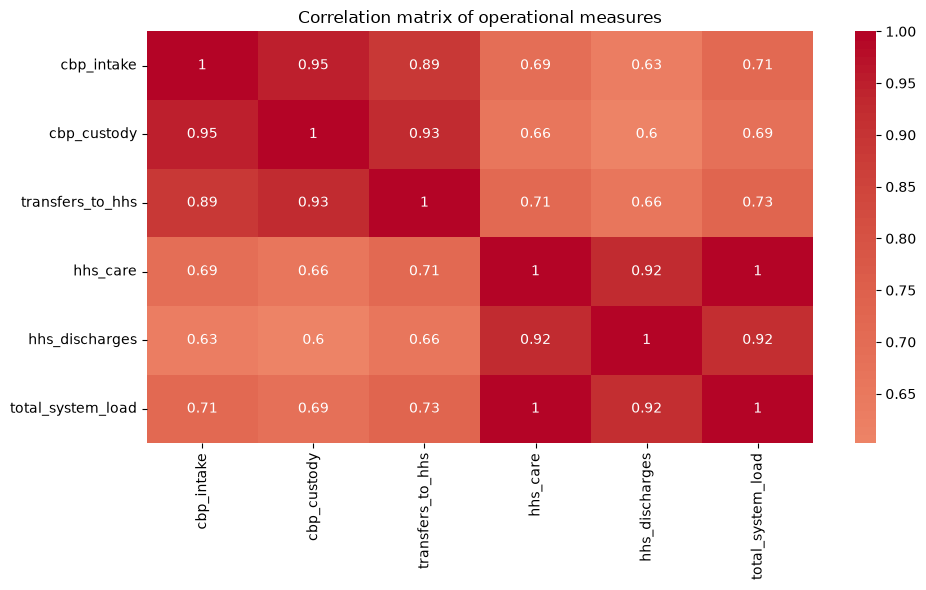

In [5]:
plt.figure(figsize=(10,6))
sns.heatmap(features[['cbp_intake','cbp_custody','transfers_to_hhs','hhs_care','hhs_discharges','total_system_load']].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation matrix of operational measures')
plt.tight_layout()

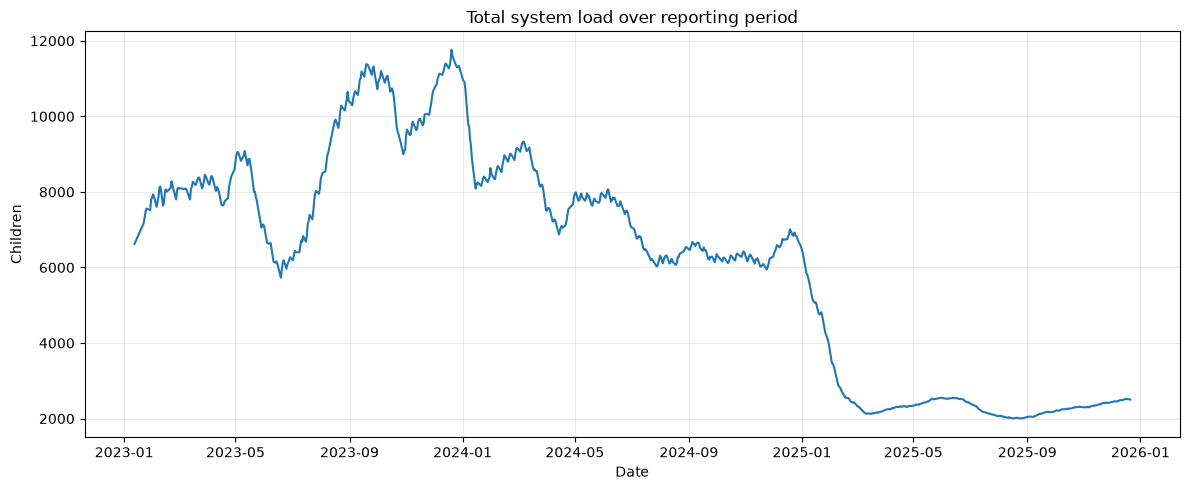

In [6]:
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(features.date, features.total_system_load)
ax.set(title='Total system load over reporting period', xlabel='Date', ylabel='Children')
ax.grid(alpha=.25)
plt.tight_layout()